# Predicting popularity: how much do the features explain together?

`01_analysis.ipynb` looked at features one at a time. This notebook asks the joint question: given
everything we know about a repo *except* signals that are caused by popularity itself, how well can
a model tell which star bucket it is in?

- **Target:** the star bucket (10–99, 100–999, 1k–9.9k, 10k+). The four classes are balanced by the
  sampling design, so random guessing scores 25%.
- **Model:** a random forest, compared with a majority-class baseline and a logistic regression.
- **Evaluation:** 5-fold cross-validation on 80% of the data, then a single check on a held-out 20%
  test set. Results are reported as macro-F1 and accuracy.
- **Importance:** permutation importance on the test set, which measures how much the score drops
  when one feature is shuffled.

The **README-only** model trained here is saved for the dashboard's README checker.

## 0. Setup

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from wgs import analysis as A
from wgs.features.readme import FEATURE_NAMES as README_FEATURES

A.set_style()
SEED = 42
data = A.load()
repos = data.repos.copy()
BUCKETS = A.BUCKET_ORDER
print(f"{len(repos):,} repos, scikit-learn {sklearn.__version__}")

4,000 repos, scikit-learn 1.9.1


## 1. Features, and what is left out

The fields below are **excluded on purpose**, because they are consequences of popularity rather
than characteristics a repo has before it becomes popular. Including them would let the model
"predict" stars from things that only exist because of stars.

| Excluded | Why |
|---|---|
| stars, stars per day, log stars | the target itself |
| forks, watchers, open issues | grow in direct proportion to attention |
| GH Archive coverage, star history, milestone times | derived from the star history |

The remaining features fall into three groups:

- **README:** everything extracted from the README text, the only group a project author fully
  controls.
- **Metadata:** age, size, topics, homepage, description length, licence, language group, and
  whether the repo is a list.
- **Activity:** commits and active weeks in the last 52 weeks, days since the last push, and
  whether the repo is archived. These are the most ambiguous, because popular repos get more
  contributions, so activity is partly an *effect* of popularity too.

In [2]:
METADATA = ["age_days", "size_kb", "n_topics", "has_homepage", "description_words", "is_list_repo", "has_license"]
CATEGORICAL = ["lang_group", "license_group"]
ACTIVITY = ["commits_52w", "active_weeks_52", "days_since_push", "archived"]

X_all = pd.get_dummies(repos[README_FEATURES + METADATA + ACTIVITY + CATEGORICAL], columns=CATEGORICAL, dtype=float)
X_all = X_all.astype(float).fillna(-1)  # 5 repos without commit statistics
y = repos["bucket"].astype(str)

meta_cols = METADATA + [c for c in X_all.columns if c.startswith(tuple(f"{c}_" for c in CATEGORICAL))]
feature_sets = {
    "README only": README_FEATURES,
    "Metadata only": meta_cols,
    "README + metadata": README_FEATURES + meta_cols,
    "All (incl. activity)": list(X_all.columns),
}
family = {**{c: "README" for c in README_FEATURES}, **{c: "Metadata" for c in meta_cols},
          **{c: "Activity" for c in ACTIVITY}}
pd.Series({k: len(v) for k, v in feature_sets.items()}).to_frame("features")

,features
README only,16
Metadata only,32
README + metadata,48
All (incl. activity),52


## 2. Train/test split and cross-validation

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X_all, y, test_size=0.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def forest():
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=5, max_features="sqrt",
                                  n_jobs=-1, random_state=SEED)

models = {
    ("Majority class", "All (incl. activity)"): DummyClassifier(strategy="most_frequent"),
    ("Logistic regression", "All (incl. activity)"): make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    **{("Random forest", name): forest() for name in feature_sets},
}

rows = []
for (model_name, set_name), model in models.items():
    cols = feature_sets[set_name]
    scores = cross_validate(model, X_train[cols], y_train, cv=cv, scoring=["f1_macro", "accuracy"])
    rows.append({"model": model_name, "features": set_name,
                 "macro_f1": scores["test_f1_macro"].mean(), "macro_f1_sd": scores["test_f1_macro"].std(),
                 "accuracy": scores["test_accuracy"].mean()})
cv_results = pd.DataFrame(rows)
cv_results.round(3)

,model,features,macro_f1,macro_f1_sd,accuracy
0,Majority class,All (incl. activity),0.100,0.000,0.250
1,Logistic regression,All (incl. activity),0.504,0.020,0.511
2,Random forest,README only,0.451,0.007,0.460
3,Random forest,Metadata only,0.460,0.018,0.472
4,Random forest,README + metadata,0.492,0.009,0.501
5,Random forest,All (incl. activity),0.516,0.013,0.522


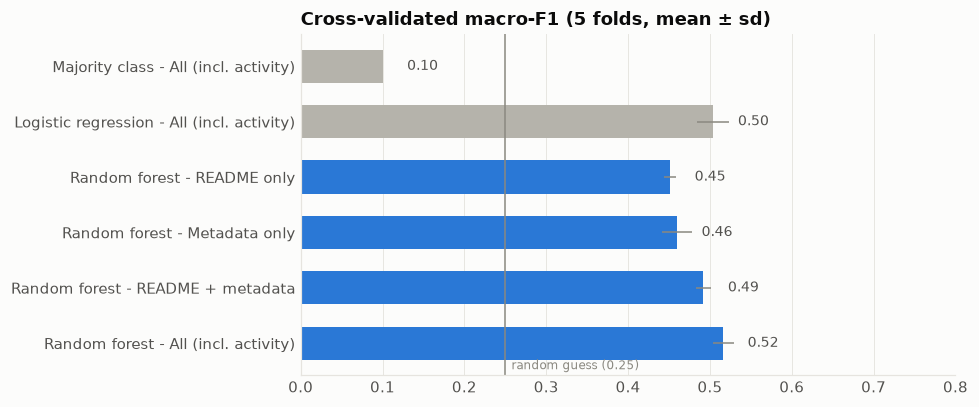

In [4]:
res = cv_results.iloc[::-1].reset_index(drop=True)
labels = [f"{m} - {f}" if m != "Random forest" else f"Random forest - {f}" for m, f in zip(res["model"], res["features"])]
colors = [A.CATEGORICAL[0] if m == "Random forest" else A.MUTED for m in res["model"]]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(labels, res["macro_f1"], xerr=res["macro_f1_sd"], color=colors, height=0.6,
        error_kw={"ecolor": A.INK["muted"], "elinewidth": 1})
for yv, v in enumerate(res["macro_f1"]):
    ax.text(v + 0.03, yv, f"{v:.2f}", va="center", fontsize=9, color=A.INK["secondary"])
ax.axvline(0.25, color=A.INK["muted"], linewidth=1)
ax.annotate("random guess (0.25)", xy=(0.25, 0), xycoords=("data", "axes fraction"), xytext=(4, 4),
            textcoords="offset points", fontsize=8, color=A.INK["muted"])
ax.set_xlim(0, 0.8)
ax.grid(axis="y", visible=False)
ax.set_title("Cross-validated macro-F1 (5 folds, mean ± sd)")
fig.tight_layout()

Every feature set clearly beats chance (0.25), but none comes close to a confident prediction:

- **README alone** recovers part of the bucket, at about 0.45 macro-F1.
- **Metadata alone** does about as well.
- **Combining README and metadata** helps a little.
- **Adding activity** gives the best model, at about 0.5.

Logistic regression nearly matches the forest (0.50 against 0.52), so the signal is mostly simple
and monotonic, and the ceiling is low whichever model is used. Whatever separates a 1,000-star repo from a 100-star one is mostly *not* in these
measurable characteristics. The missing ingredients include the usefulness of the software, timing,
the author's audience, and luck.

## 3. Held-out test set

In [5]:
full_cols = feature_sets["All (incl. activity)"]
full_model = forest().fit(X_train[full_cols], y_train)
pred = full_model.predict(X_test[full_cols])
print(f"Test macro-F1 {f1_score(y_test, pred, average='macro'):.3f}, accuracy {accuracy_score(y_test, pred):.3f}\n")
print(classification_report(y_test, pred, labels=BUCKETS, target_names=[A.BUCKET_LABELS[b] for b in BUCKETS], digits=3))

Test macro-F1 0.516, accuracy 0.520

              precision    recall  f1-score   support

       10–99      0.615     0.655     0.634       200
     100–999      0.383     0.320     0.349       200
     1k–9.9k      0.427     0.470     0.448       200
        10k+      0.635     0.635     0.635       200

    accuracy                          0.520       800
   macro avg      0.515     0.520     0.516       800
weighted avg      0.515     0.520     0.516       800



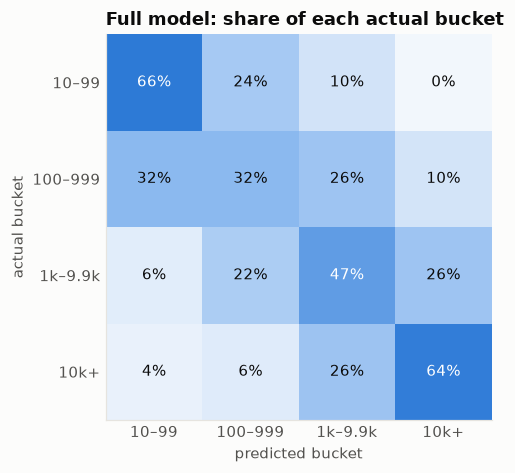

In [6]:
def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=BUCKETS, normalize="true") * 100
    from matplotlib.colors import LinearSegmentedColormap
    cmap = LinearSegmentedColormap.from_list("seq", ["#f4f8fd", "#86b6ef", "#2a78d6", "#0d366b"])
    fig, ax = plt.subplots(figsize=(5.2, 4.4))
    ax.imshow(cm, cmap=cmap, vmin=0, vmax=100)
    names = [A.BUCKET_LABELS[b] for b in BUCKETS]
    ax.set_xticks(range(4), names)
    ax.set_yticks(range(4), names)
    ax.set_xlabel("predicted bucket")
    ax.set_ylabel("actual bucket")
    ax.grid(visible=False)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{cm[i, j]:.0f}%", ha="center", va="center", fontsize=10,
                    color="white" if cm[i, j] > 45 else A.INK["primary"])
    ax.set_title(title)
    fig.tight_layout()

plot_confusion(y_test, pred, "Full model: share of each actual bucket")

The extremes are easiest: 10–99 star repos and 10k+ repos are recognised most often. Most mistakes
land in a **neighbouring** bucket, and the model rarely confuses a tiny repo with a huge one. So it
has learned an ordered "size" signal, but it cannot place a repo within one order of magnitude
reliably.

## 4. Which features matter?

,total importance
family,
Metadata,0.065
README,0.065
Activity,0.038


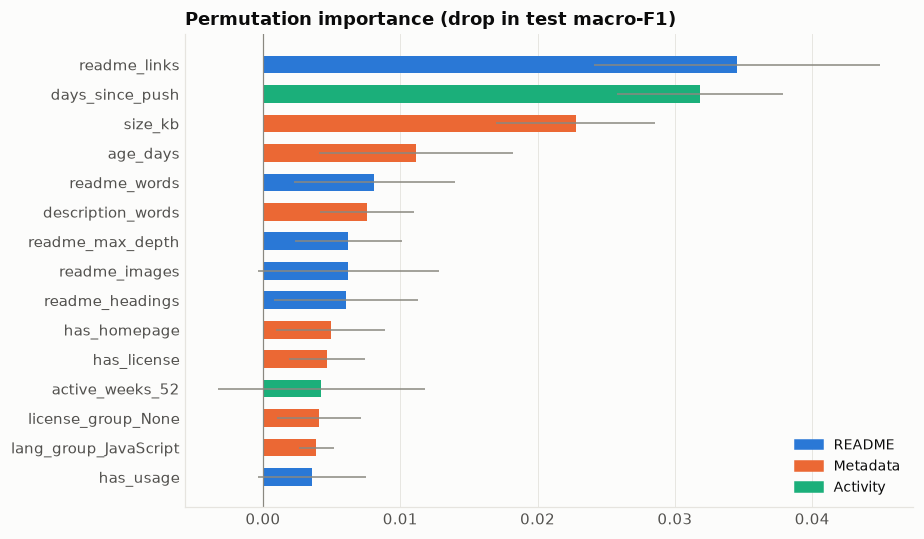

In [7]:
perm = permutation_importance(full_model, X_test[full_cols], y_test, scoring="f1_macro",
                              n_repeats=10, random_state=SEED)
imp = pd.DataFrame({"feature": full_cols, "importance": perm.importances_mean, "sd": perm.importances_std})
imp["family"] = imp["feature"].map(family).fillna("Metadata")
top = imp.sort_values("importance", ascending=False).head(15).iloc[::-1]

fam_colors = {"README": A.CATEGORICAL[0], "Metadata": A.CATEGORICAL[1], "Activity": A.CATEGORICAL[2]}
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(top["feature"], top["importance"], xerr=top["sd"], color=top["family"].map(fam_colors), height=0.6,
        error_kw={"ecolor": A.INK["muted"], "elinewidth": 1})
ax.axvline(0, color=A.INK["muted"], linewidth=0.8)
ax.grid(axis="y", visible=False)
ax.set_title("Permutation importance (drop in test macro-F1)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=f) for f, c in fam_colors.items()],
          loc="lower right", fontsize=9)
fig.tight_layout()
imp.groupby("family")["importance"].sum().sort_values(ascending=False).round(3).to_frame("total importance")

Four features stand out:

- **Links in the README**, which point to docs, sites, packages and related projects.
- **Days since the last push.**
- **Repository size.**
- **Age.**

After those come README length and structure, description length, a homepage and a licence. Badges
and topics are not in the top 15: once links and activity are known, they add little. Even the top
feature only costs about 3–4 points of F1 when shuffled, because correlated features (Section 8 of
the analysis notebook) can stand in for each other. Read this as "these characteristics travel
together with popularity", not as a recipe.

## 5. README-only model (used by the dashboard)

The dashboard's README checker only sees a README, so it uses a model trained on README features
alone. The cell below evaluates it on the same held-out test set, then refits it on all the data
and saves it.

{'test_macro_f1': 0.458, 'test_accuracy': 0.463}


,importance
readme_links,0.1286
readme_code_blocks,0.0242
readme_images,0.0223
readme_words,0.0187
has_usage,0.0157
has_contributing,0.0073
readme_decorations,0.0071
readme_headings,0.0068
readme_max_depth,0.0037
has_demo_section,0.0032


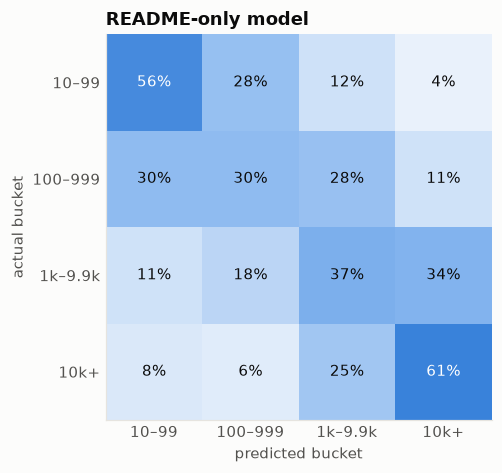

In [8]:
readme_model = forest().fit(X_train[README_FEATURES], y_train)
readme_pred = readme_model.predict(X_test[README_FEATURES])
readme_metrics = {
    "test_macro_f1": round(float(f1_score(y_test, readme_pred, average="macro")), 3),
    "test_accuracy": round(float(accuracy_score(y_test, readme_pred)), 3),
}
print(readme_metrics)
plot_confusion(y_test, readme_pred, "README-only model")

perm_r = permutation_importance(readme_model, X_test[README_FEATURES], y_test, scoring="f1_macro",
                                n_repeats=10, random_state=SEED)
readme_importance = (pd.Series(perm_r.importances_mean, index=README_FEATURES)
                     .clip(lower=0).sort_values(ascending=False))
readme_importance.round(4).to_frame("importance")

Within the README-only model, **the number of links dominates**, followed at a distance by code
blocks, content images, length and a usage section. Links are a good proxy for an *ecosystem* around
a project, such as documentation sites, package registries, demos and related tools. The README
checker uses these importances to weight its feedback.

In [9]:
final_model = forest().fit(X_all[README_FEATURES], y)
models_dir = ROOT / "models"
models_dir.mkdir(exist_ok=True)
joblib.dump(final_model, models_dir / "readme_rf.joblib", compress=3)
meta = {
    "description": "Random forest predicting the star bucket from README features only.",
    "features": README_FEATURES,
    "classes": list(final_model.classes_),
    "class_labels": A.BUCKET_LABELS,
    "metrics_on_held_out_test": readme_metrics,
    "permutation_importance": readme_importance.round(5).to_dict(),
    "trained_on": int(len(y)),
    "snapshot": data.report["snapshot"],
    "sklearn_version": sklearn.__version__,
    "random_state": SEED,
}
(models_dir / "readme_rf.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
print(f"saved models/readme_rf.joblib ({(models_dir / 'readme_rf.joblib').stat().st_size / 1e6:.1f} MB) and models/readme_rf.json")

saved models/readme_rf.joblib (5.3 MB) and models/readme_rf.json


## 6. Conclusions and limitations

- **Modest predictive power.** README, metadata and activity features together place a repo in
  the right star bucket about half the time (macro-F1 ≈ 0.5, against 0.25 for guessing), and
  mistakes are mostly off by one bucket.
- **README alone carries some signal** (≈ 0.45), similar to metadata alone. It is enough to say
  whether a README *looks like* those of popular repos, which is how the dashboard uses it, but not
  enough to predict a project's success.
- **What matters most:** README links, how recently the repo was pushed to, repository size and
  age. Badges and topics add little once those are known. All of these are correlated with one
  another, so their individual importances should not be over-read.

**Limitations.**

- **No causal reading.** These are associations in a cross-sectional snapshot. Several features,
  especially activity, badges and contributing sections, are plausibly results of popularity.
- **Artificial class balance.** The classes are balanced by the sampling design. On real GitHub,
  10–99 star repos outnumber 10k+ repos by about 440 to 1, so a model applied to arbitrary repos
  would need its probabilities re-calibrated to those base rates. The dashboard shows *which
  bucket's READMEs this one resembles*, not the chance of reaching it.
- **Small classes per subgroup.** 4,000 repos is enough for overall estimates but thin for specific
  language × bucket combinations.